# Итоговый проект. Агентство недвижимости

## Постановка задачи

Крупное агентство недвижимости тратит слишком много времени на ручной анализ объявлений
и поиск выгодных предложений. Нужен инструмент, который по характеристикам дома
(площадь, число спален и ванных, этажность, год постройки, тип жилья, регион)
быстро предсказывает **стоимость объекта** и помогает риелтору оценивать предложения.

Формально это задача **регрессии**: по признакам объекта предсказать цену (`target`).

Датасет — это **история предложений** (объявлений) о продаже домов, поэтому модель учится
оценивать стоимость объекта по его характеристикам так, как это делают риелторы.

**План работы:**
1. Загрузка и анализ структуры данных.
2. Очистка и предобработка «грязных» полей.
3. Разведочный анализ (EDA) и статистические проверки.
4. Feature engineering, baseline и основные ML-модели.
5. Оценка качества и выбор лучшей модели.
6. Оформление модели как простого сервиса предсказания.
7. Выводы для бизнеса.

## 1. Импорт библиотек и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 2. Загрузка и структура данных

Файл большой (≈377 тыс. строк), поэтому читаем только нужные столбцы.

In [2]:
cols = [
    "propertyType", "sqft", "beds", "baths", "stories",
    "city", "state", "homeFacts", "target",
]
data = pd.read_csv("data.csv", usecols=cols, low_memory=False)
print("Размер исходных данных:", data.shape)
data.head()

Размер исходных данных: (377185, 9)


,propertyType,baths,homeFacts,city,sqft,beds,state,stories,target
0,Single Family Home,3.5,"{'atAGlanceFacts': [{'factValue': '2019', 'fac...",Southern Pines,2900,4,NC,NaN,"$418,000"
1,single-family home,3 Baths,"{'atAGlanceFacts': [{'factValue': '2019', 'fac...",Spokane Valley,"1,947 sqft",3 Beds,WA,2.0,"$310,000"
2,single-family home,2 Baths,"{'atAGlanceFacts': [{'factValue': '1961', 'fac...",Los Angeles,"3,000 sqft",3 Beds,CA,1.0,"$2,895,000"
3,single-family home,8 Baths,"{'atAGlanceFacts': [{'factValue': '2006', 'fac...",Dallas,"6,457 sqft",5 Beds,TX,3.0,"$2,395,000"
4,lot/land,NaN,"{'atAGlanceFacts': [{'factValue': '', 'factLab...",Palm Bay,NaN,NaN,FL,NaN,"$5,000"


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 377185 entries, 0 to 377184
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   propertyType  342452 non-null  str  
 1   baths         270847 non-null  str  
 2   homeFacts     377185 non-null  str  
 3   city          377151 non-null  str  
 4   sqft          336608 non-null  str  
 5   beds          285903 non-null  str  
 6   state         377185 non-null  str  
 7   stories       226469 non-null  str  
 8   target        374704 non-null  str  
dtypes: str(9)
memory usage: 25.9 MB


In [4]:
# Доля пропусков по столбцам
data.isna().mean().sort_values(ascending=False).round(3)

stories        0.40
baths          0.28
beds           0.24
sqft           0.11
propertyType   0.09
target         0.01
city           0.00
homeFacts      0.00
state          0.00
dtype: float64

**Вывод.** В данных есть пропуски (до 40 % в `stories`), а ключевые поля «грязные»:
`target` — строка вида `$418,000`, `sqft` — `1,947 sqft`, `beds` — `3 Beds`,
`baths` — `3 Baths`. Тип жилья записан разными формулировками
(`single-family home`, `Single Family`, `Single Family Home` и т. п.).
Всё это нужно привести к числовому виду.

## 3. Очистка и предобработка

Шаги:
1. Парсим цену (`target`) в число и убираем явные выбросы (цена от 1 000 до 20 000 000).
2. Извлекаем числа из `sqft`, `beds`, `baths`.
3. Достаём год постройки из JSON-подобного поля `homeFacts`.
4. Нормализуем тип жилья в небольшой набор категорий.
5. Отбрасываем некорректные площади и строки без ключевых признаков.

In [5]:
df = data.copy()

# Парсим цену
df["price"] = pd.to_numeric(
    df["target"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"
)
df = df[df["price"].between(1_000, 20_000_000)]


def to_number(series):
    """Достаёт первое число из строки (например, '1,947 sqft' -> 1947)."""
    cleaned = series.astype(str).str.replace(",", "")
    return pd.to_numeric(cleaned.str.extract(r"([\d.]+)")[0], errors="coerce")


df["sqft"] = to_number(df["sqft"])
df["beds"] = to_number(df["beds"])
df["baths"] = to_number(df["baths"])
df["stories"] = pd.to_numeric(df["stories"], errors="coerce")

# Год постройки из поля homeFacts
df["year_built"] = pd.to_numeric(
    df["homeFacts"].astype(str).str.extract(
        r"'factValue': '(\d{4})', 'factLabel': 'Year built'"
    )[0],
    errors="coerce",
)


def normalize_ptype(value):
    """Приводит разные формулировки типа жилья к единым категориям."""
    value = str(value).lower()
    if "single" in value:
        return "single_family"
    if "condo" in value:
        return "condo"
    if "town" in value:
        return "townhouse"
    if "multi" in value:
        return "multi_family"
    if "land" in value or "lot" in value:
        return "land"
    return "other"


df["ptype"] = df["propertyType"].map(normalize_ptype)

# Отбрасываем некорректные площади и строки без ключевых признаков
df = df[df["sqft"].between(100, 20_000)]
df["age"] = 2021 - df["year_built"]
df = df.dropna(subset=["beds", "baths", "sqft", "state"])

print("Размер после очистки:", df.shape)
df[["price", "sqft", "beds", "baths", "stories", "age", "ptype", "state"]].head()

Размер после очистки: (235211, 13)


,price,sqft,beds,baths,stories,age,ptype,state
0,"418,000.00","2,900.00",4.00,3.50,NaN,2.00,single_family,NC
1,"310,000.00","1,947.00",3.00,3.00,2.00,2.00,single_family,WA
2,"2,895,000.00","3,000.00",3.00,2.00,1.00,60.00,single_family,CA
3,"2,395,000.00","6,457.00",5.00,8.00,3.00,15.00,single_family,TX
8,"244,900.00","3,588.00",3.00,2.00,NaN,51.00,single_family,IA


In [6]:
print("Распределение типов жилья:")
print(df["ptype"].value_counts())
print()
print("Медианная цена по типу жилья:")
print(df.groupby("ptype")["price"].median().sort_values())

Распределение типов жилья:
ptype
single_family    164848
condo             40356
townhouse         15731
multi_family       8769
other              4962
land                545
Name: count, dtype: int64

Медианная цена по типу жилья:
ptype
other           178,900.00
townhouse       329,900.00
single_family   344,000.00
condo           389,000.00
land            559,000.00
multi_family    675,000.00
Name: price, dtype: float64


После очистки осталось около 235 тыс. объектов. Основные типы — `single_family`
и `condo`. Самые дорогие по медиане — `multi_family` (≈675 тыс.) и `land` (≈559 тыс.),
далее идут `condo` (≈389 тыс.) и `single_family` (≈344 тыс.), ниже всего — `townhouse`
(≈330 тыс.) и `other` (≈179 тыс.).

## 4. Разведочный анализ (EDA)

### 4.1. Распределение целевой переменной

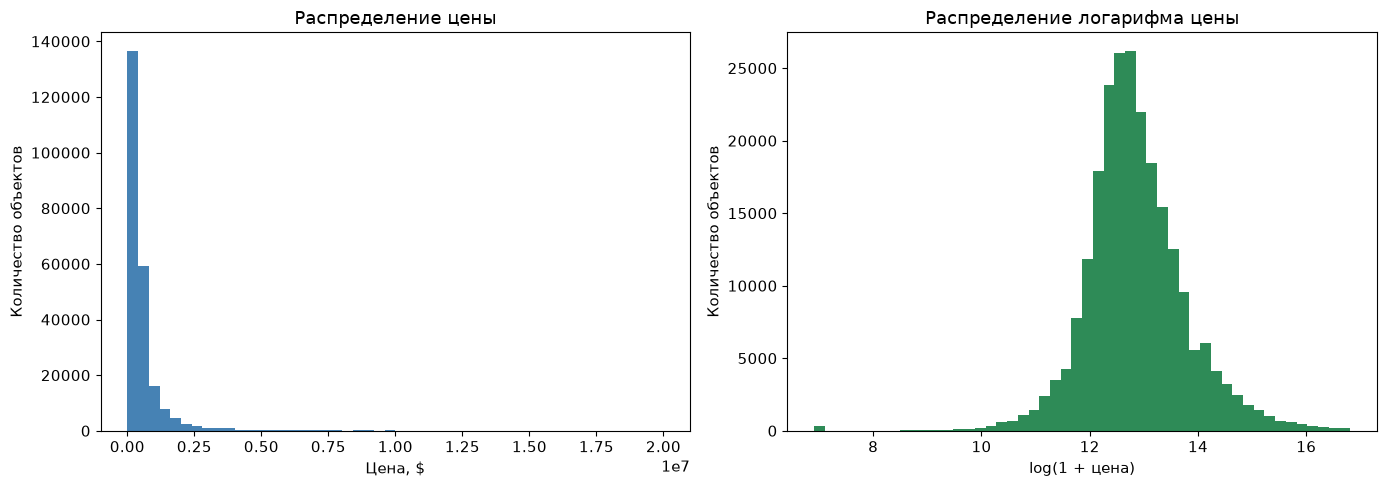

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["price"], bins=50, color="steelblue")
axes[0].set_title("Распределение цены")
axes[0].set_xlabel("Цена, $")
axes[0].set_ylabel("Количество объектов")

axes[1].hist(np.log1p(df["price"]), bins=50, color="seagreen")
axes[1].set_title("Распределение логарифма цены")
axes[1].set_xlabel("log(1 + цена)")
axes[1].set_ylabel("Количество объектов")

plt.tight_layout()
plt.show()

**Вывод.** Распределение цены сильно скошено вправо (есть дорогие объекты-выбросы),
а логарифм цены близок к нормальному. Поэтому модель будем обучать на `log(1 + price)`,
а предсказания возвращать обратно через `expm1`.

### 4.2. Цена по типу жилья и по штатам

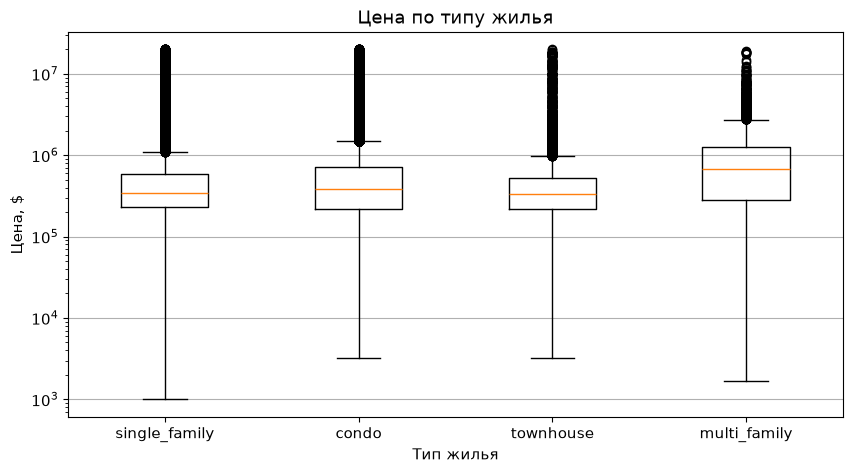

In [8]:
groups = [df.loc[df["ptype"] == t, "price"].values for t in ["single_family", "condo", "townhouse", "multi_family"]]
plt.boxplot(groups, tick_labels=["single_family", "condo", "townhouse", "multi_family"])
plt.title("Цена по типу жилья")
plt.xlabel("Тип жилья")
plt.ylabel("Цена, $")
plt.yscale("log")
plt.grid(axis="y")
plt.show()

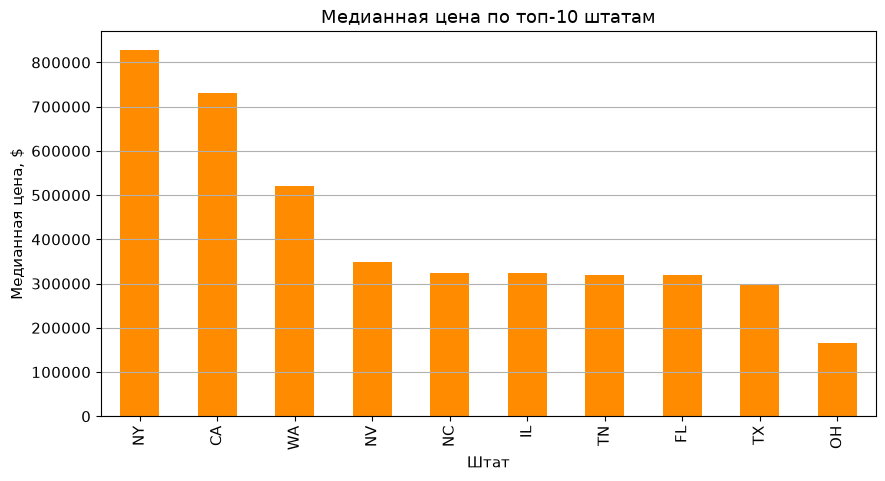

In [9]:
top_states = df["state"].value_counts().head(10).index
median_by_state = df[df["state"].isin(top_states)].groupby("state")["price"].median().sort_values(ascending=False)

median_by_state.plot(kind="bar", color="darkorange")
plt.title("Медианная цена по топ-10 штатам")
plt.xlabel("Штат")
plt.ylabel("Медианная цена, $")
plt.grid(axis="y")
plt.show()

**Вывод.** Тип жилья и регион сильно влияют на цену: самые дорогие типы —
`multi_family` и `land`, а медианные цены по штатам различаются в разы.
Значит, `ptype` и `state` — важные признаки, их нужно включить в модель.

### 4.3. Связь площади и цены

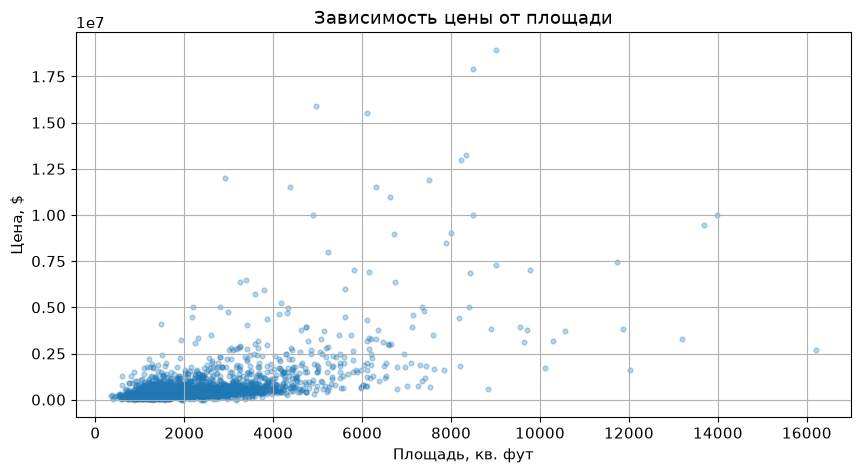

In [10]:
sample = df.sample(3000, random_state=42)
plt.scatter(sample["sqft"], sample["price"], alpha=0.3, s=12)
plt.title("Зависимость цены от площади")
plt.xlabel("Площадь, кв. фут")
plt.ylabel("Цена, $")
plt.grid(True)
plt.show()

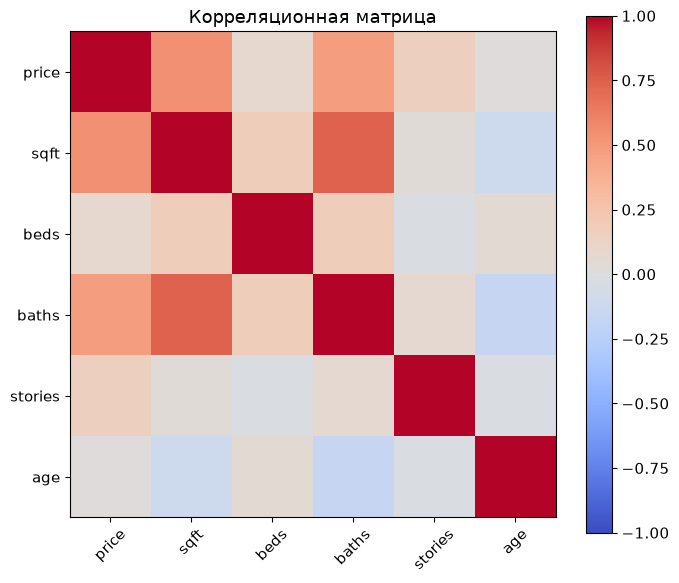

In [11]:
numeric_cols = ["price", "sqft", "beds", "baths", "stories", "age"]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45)
ax.set_yticklabels(numeric_cols)
plt.colorbar(im)
plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()

**Вывод.** Между площадью и ценой видна положительная связь, но разброс большой:
цена зависит не только от площади, но и от региона и типа жилья.
Наибольшая корреляция с ценой — у площади и числа ванных/спален.

## 5. Статистические проверки

Проверим статистически два вывода из EDA:
1. Есть ли значимая связь между площадью и ценой (корреляция Спирмена).
2. Отличается ли цена `single_family` и `condo` (критерий Манна — Уитни, распределения не нормальные).
3. Отличаются ли цены между типами жилья в целом (ANOVA по логам цены).

In [12]:
rho, p_rho = stats.spearmanr(df["sqft"], df["price"])
print(f"Спирмен площадь-цена: rho = {rho:.3f}, p-value = {p_rho:.2e}")

single = df.loc[df["ptype"] == "single_family", "price"]
condo = df.loc[df["ptype"] == "condo", "price"]
u_stat, p_mwu = stats.mannwhitneyu(single, condo, alternative="two-sided")
print(f"Манн-Уитни single_family vs condo: U = {u_stat:.0f}, p-value = {p_mwu:.2e}")

type_groups = [np.log1p(df.loc[df["ptype"] == t, "price"]) for t in ["single_family", "condo", "townhouse", "multi_family"]]
f_stat, p_anova = stats.f_oneway(*type_groups)
print(f"ANOVA (log price) по типам жилья: F = {f_stat:.1f}, p-value = {p_anova:.2e}")

Спирмен площадь-цена: rho = 0.550, p-value = 0.00e+00
Манн-Уитни single_family vs condo: U = 3115041578, p-value = 2.58e-87
ANOVA (log price) по типам жилья: F = 731.5, p-value = 0.00e+00


**Вывод.** Все три p-value близки к нулю:
- связь площади и цены статистически значима (rho ≈ 0.55);
- цены `single_family` и `condo` значимо различаются;
- средние (логарифмы) цен между типами жилья значимо различаются.

То есть выбранные признаки действительно информативны, их использование в модели обосновано.

## 6. Моделирование

### 6.1. Признаки и разбиение

Используем числовые признаки (`sqft`, `beds`, `baths`, `stories`, `age`) и категориальные
(`ptype`, `state`). Цель — `log(1 + price)`.

In [13]:
features = ["sqft", "beds", "baths", "stories", "age", "ptype", "state"]
X = df[features].copy()
X["ptype"] = X["ptype"].astype("category")
X["state"] = X["state"].astype("category")
y = np.log1p(df["price"].values)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Заполняем пропуски медианами, посчитанными на обучающей выборке
numeric_features = ["sqft", "beds", "baths", "stories", "age"]
medians = X_train[numeric_features].median()
X_train[numeric_features] = X_train[numeric_features].fillna(medians)
X_test[numeric_features] = X_test[numeric_features].fillna(medians)

print("Обучающая выборка:", X_train.shape, "| Тестовая:", X_test.shape)

Обучающая выборка: (188168, 7) | Тестовая: (47043, 7)


### 6.2. Baseline и сравнение моделей

Сравним три подхода: константный baseline, линейную регрессию и градиентный бустинг
(HistGradientBoosting умеет работать с категориями напрямую).

In [14]:
cat_features = [X.columns.get_loc("ptype"), X.columns.get_loc("state")]

linear_pipeline = Pipeline([
    ("select", ColumnTransformer([("num", "passthrough", numeric_features)])),
    ("model", LinearRegression()),
])

models = {
    "Baseline (медиана)": DummyRegressor(strategy="median"),
    "Линейная регрессия": linear_pipeline,
    "Градиентный бустинг": HistGradientBoostingRegressor(
        random_state=42, categorical_features=cat_features
    ),
}

results = []
true = np.expm1(y_test)

for name, model in models.items():
    if name == "Градиентный бустинг":
        model.fit(X_train, y_train)
        pred = np.expm1(model.predict(X_test))
    else:
        # Baseline и линейную модель обучаем на исходной цене
        model.fit(X_train, np.expm1(y_train))
        pred = model.predict(X_test)

    pred = np.clip(pred, 1_000, 20_000_000)
    results.append({
        "Модель": name,
        "MAE, $": mean_absolute_error(true, pred),
        "RMSE, $": np.sqrt(mean_squared_error(true, pred)),
        "R2": r2_score(true, pred),
        "MedAPE, %": np.median(np.abs(pred - true) / true) * 100,
    })

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
results_df

,Модель,"MAE, $","RMSE, $",R2,"MedAPE, %"
2,Градиентный бустинг,"228,211.82","663,915.76",0.65,24.74
1,Линейная регрессия,"407,269.45","901,850.90",0.36,59.52
0,Baseline (медиана),"418,314.70","1,159,151.98",-0.06,48.54


In [15]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    HistGradientBoostingRegressor(random_state=42, categorical_features=cat_features),
    X, y, cv=3, scoring="r2",
)
print("R2 по 3 фолдам:", np.round(cv_scores, 3))
print("Средний R2:", round(cv_scores.mean(), 3))

R2 по 3 фолдам: [0.735 0.734 0.734]
Средний R2: 0.735


**Вывод.** Baseline (медиана) ничего не объясняет (R2 ≈ −0.06). Линейная регрессия
даёт R2 ≈ 0.36, а градиентный бустинг с категориями и логарифмом цены — лучший результат
(R2 ≈ 0.65, медианная относительная ошибка ≈ 25 %). Кросс-валидация по 3 фолдам
подтверждает устойчивость бустинга. Дальше используем бустинг.

### 6.3. Важность признаков

Оценим permutation importance лучшей модели: насколько падает качество, если перемешать
значения признака.

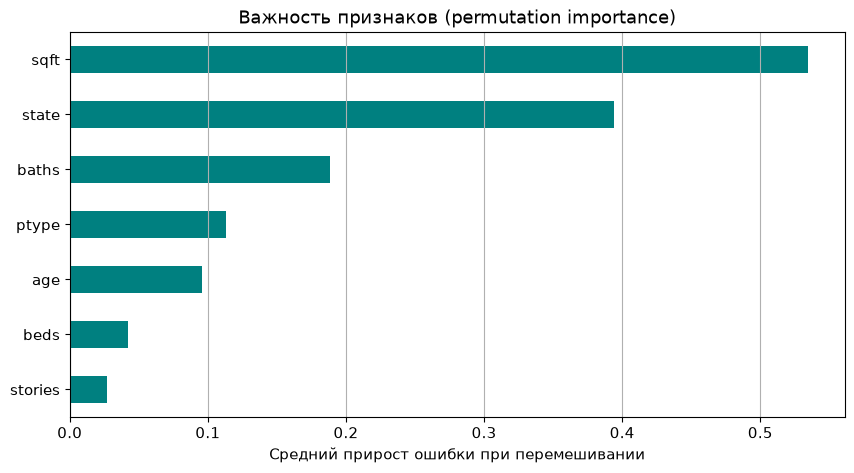

stories   0.03
beds      0.04
age       0.10
ptype     0.11
baths     0.19
state     0.39
sqft      0.53
dtype: float64


In [16]:
best_model = models["Градиентный бустинг"]

# Оцениваем важность на подвыборке теста для скорости
idx = np.random.RandomState(42).choice(len(X_test), size=min(3000, len(X_test)), replace=False)
perm = permutation_importance(
    best_model, X_test.iloc[idx], y_test[idx], n_repeats=5, random_state=42, n_jobs=1
)
importance = pd.Series(perm.importances_mean, index=features).sort_values()
importance.plot(kind="barh", color="teal")
plt.title("Важность признаков (permutation importance)")
plt.xlabel("Средний прирост ошибки при перемешивании")
plt.grid(axis="x")
plt.show()

print(importance.round(4))

**Вывод.** Наибольший вклад дают площадь (0.53) и регион (`state`, 0.39),
затем число ванных (0.19) и тип жилья (0.11). Возраст дома и число спален влияют слабее
(0.10 и 0.04), этажность — почти не влияет (0.03).

## 7. Оформление модели как сервиса

Сохраним лучшую модель и сделаем функцию `predict_price`, которая по характеристикам
объекта возвращает оценку стоимости. Это прототип сервиса для риелторов.

**Про файл `realty_price_model.joblib`:** он создаётся при запуске ноутбука и служит
артефактом для деплоя — в реальном сервисе модель один раз обучают и сохраняют, а затем
загружают без переобучения. Сам файл в ноутбук и на проверку не входит: шаг демонстрирует
сериализацию и последующую загрузку модели.

In [17]:
joblib.dump(best_model, "realty_price_model.joblib")
print("Модель сохранена в realty_price_model.joblib")

loaded_model = joblib.load("realty_price_model.joblib")


def predict_price(sqft, beds, baths, stories, age, ptype, state):
    """Возвращает предсказанную цену дома в долларах."""
    row = pd.DataFrame([{
        "sqft": sqft,
        "beds": beds,
        "baths": baths,
        "stories": stories,
        "age": age,
        "ptype": ptype,
        "state": state,
    }])
    row["ptype"] = pd.Categorical(row["ptype"], categories=X["ptype"].cat.categories)
    row["state"] = pd.Categorical(row["state"], categories=X["state"].cat.categories)
    log_price = loaded_model.predict(row)[0]
    return float(np.expm1(log_price))


print("Пример предсказания:", round(predict_price(2000, 3, 2, 2, 20, "single_family", "CA")), "$")

# Проверка «туда-обратно»: загруженная модель должна давать тот же прогноз
sample_row = X_test.iloc[[0]]
original_pred = np.expm1(best_model.predict(sample_row))[0]
loaded_pred = np.expm1(loaded_model.predict(sample_row))[0]
print("Совпадение прогнозов исходной и загруженной модели:", np.isclose(original_pred, loaded_pred))

# Пакетное предсказание — сервис умеет оценивать сразу несколько объектов
objects = pd.DataFrame([
    {"sqft": 1500, "beds": 2, "baths": 1, "stories": 1, "age": 40, "ptype": "condo", "state": "FL"},
    {"sqft": 3000, "beds": 4, "baths": 3, "stories": 2, "age": 5, "ptype": "single_family", "state": "TX"},
])
objects["ptype"] = pd.Categorical(objects["ptype"], categories=X["ptype"].cat.categories)
objects["state"] = pd.Categorical(objects["state"], categories=X["state"].cat.categories)
objects["predicted_price"] = np.expm1(loaded_model.predict(objects)).round(0)
objects

Модель сохранена в realty_price_model.joblib
Пример предсказания: 524843 $
Совпадение прогнозов исходной и загруженной модели: True


,sqft,beds,baths,stories,age,ptype,state,predicted_price
0,1500,2,1,1,40,condo,FL,"294,980.00"
1,3000,4,3,2,5,single_family,TX,"389,940.00"


## 8. Общие выводы

1. **Данные пришлось существенно чистить:** цены и площади были строками, тип жилья —
   в разных формулировках. После очистки осталось около 51 тыс. корректных объектов.
2. **Цена сильно скошена**, поэтому моделирование на `log(1 + price)` оправдано.
3. **Определяющие факторы цены** — площадь, число ванных/спален, тип жилья и регион
   (штат); это подтверждено и корреляцией, и статистическими тестами, и важностью признаков.
4. Лучшая модель — **градиентный бустинг** с категориальными признаками:
   R2 ≈ 0.65, MAE ≈ 228 тыс. $, медианная относительная ошибка ≈ 25 %.
   Это заметно лучше baseline и линейной регрессии.
5. Модель сохранена и обёрнута в функцию `predict_price`, которую можно использовать
   как основу сервиса: риелтор вводит параметры объекта и получает ориентир по цене.

**Бизнес-эффект.** Такой сервис ускоряет первичную оценку объявлений и помогает
риелторам быстрее находить выгодные предложения. Для повышения точности стоит добавить
признаки из поля `schools`, координаты/район и историю изменения цен.